# 2.0 Prueba P1 (Regresión): Predicción de Viajes Diarios por Estación

**Objetivo:** Formular, construir variables sin fuga temporal y evaluar el modelo base (*Seasonal Naive*) y un modelo candidato (*Ridge Regression*) para predecir cuántos viajes se iniciarán por estación en el día siguiente (horizonte de 24 horas).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from mi_bici.config import PROCESSED_DATA_DIR

RANDOM_SEED = 42
trips = pd.read_parquet(PROCESSED_DATA_DIR / 'trips.parquet')
stations = pd.read_parquet(PROCESSED_DATA_DIR / 'stations.parquet')
print(f'Viajes cargados: {len(trips):,} | Estaciones: {len(stations)}')

2026-10-18 15:35:14.975 | INFO     | mi_bici.config:<module>:11 - PROJ_ROOT path is: /Users/poncho_stark/Documents/Tec/4to-tri/mlops/TC5061-Proyecto-Equipo11


Viajes cargados: 12,540,018 | Estaciones: 484


## 1. Agregación diaria y construcción de rezagos (sin fuga temporal)
Contamos los viajes iniciados por estación y fecha (`date`). Para que los rezagos de 1, 7, 14 y 21 días correspondan exactamente a días calendario previos, creamos la malla completa `(station_id, date)` para las estaciones activas rellenando con 0 los días sin viajes.

In [2]:
trips['date'] = trips['start_time'].dt.floor('D')
daily_counts = (
    trips.groupby(['origin_id', 'date'], as_index=False)
    .size()
    .rename(columns={'origin_id': 'station_id', 'size': 'trips_count'})
)

active_stations = stations.loc[stations['is_active'], ['station_id', 'capacity', 'zone']].copy()
all_dates = pd.date_range(trips['date'].min(), trips['date'].max(), freq='D')

grid = pd.MultiIndex.from_product(
    [active_stations['station_id'].unique(), all_dates],
    names=['station_id', 'date'],
).to_frame().reset_index(drop=True)

df_p1 = grid.merge(daily_counts, on=['station_id', 'date'], how='left')
df_p1['trips_count'] = df_p1['trips_count'].fillna(0).astype(float)
df_p1 = df_p1.merge(active_stations, on='station_id', how='inner')
df_p1 = df_p1.sort_values(['station_id', 'date']).reset_index(drop=True)

# Rezagos estrictamente del pasado por estación
grp = df_p1.groupby('station_id')['trips_count']
df_p1['lag_1d'] = grp.shift(1)
df_p1['lag_7d'] = grp.shift(7)
df_p1['lag_14d'] = grp.shift(14)
df_p1['lag_21d'] = grp.shift(21)
df_p1['rolling_mean_7d'] = grp.shift(1).rolling(7).mean()

# Variables de calendario
df_p1['day_of_week'] = df_p1['date'].dt.dayofweek
df_p1['month'] = df_p1['date'].dt.month
df_p1['is_weekend'] = (df_p1['day_of_week'] >= 5).astype(int)

# Festivos fijos principales en México
fixed_holidays = {(1, 1), (2, 5), (3, 18), (5, 1), (9, 16), (11, 18), (12, 25)}
df_p1['is_holiday'] = df_p1['date'].apply(lambda d: int((d.month, d.day) in fixed_holidays))

# Descartar los primeros 21 días donde aún no existen todos los lags
df_p1 = df_p1.dropna(subset=['lag_1d', 'lag_7d', 'lag_14d', 'lag_21d', 'rolling_mean_7d']).reset_index(drop=True)
print(f'Filas totales en dataset P1: {len(df_p1):,}')
df_p1.head()

Filas totales en dataset P1: 462,010


,station_id,date,trips_count,capacity,zone,lag_1d,lag_7d,lag_14d,lag_21d,rolling_mean_7d,day_of_week,month,is_weekend,is_holiday
0,2,2024-01-22,105.0,15,GDL,48.0,133.0,116.0,23.0,101.000000,0,1,0,0
1,2,2024-01-23,110.0,15,GDL,105.0,109.0,93.0,98.0,97.000000,1,1,0,0
2,2,2024-01-24,98.0,15,GDL,110.0,118.0,121.0,103.0,97.142857,2,1,0,0
3,2,2024-01-25,103.0,15,GDL,98.0,111.0,110.0,99.0,94.285714,3,1,0,0
4,2,2024-01-26,96.0,15,GDL,103.0,119.0,115.0,101.0,93.142857,4,1,0,0


Cada fila representa una estación y un día, usando exclusivamente información hasta $t-1$ (`lag_1d`, `lag_7d`, `lag_14d`, `lag_21d` y `rolling_mean_7d` calculada sobre `shift(1)`). Ahora aplicamos la partición temporal estricta (`Train`: 2024–2025, `Val`: Ene–Jun 2026, `Test`: Jul–Sep 2026) antes de ajustar cualquier transformación.

In [3]:
# 2. Partición temporal estricta
train_df = df_p1[df_p1['date'] <= '2025-12-31'].copy()
val_df = df_p1[(df_p1['date'] >= '2026-01-01') & (df_p1['date'] <= '2026-06-30')].copy()
test_df = df_p1[df_p1['date'] >= '2026-07-01'].copy()

print(f'Train: {len(train_df):,} filas | Val: {len(val_df):,} filas | Test: {len(test_df):,} filas')

Train: 333,700 filas | Val: 85,070 filas | Test: 43,240 filas


## 3. Evaluación del Baseline (Seasonal Naive) vs. Modelo Candidato (Ridge Regression)
Calculamos `MAE`, `RMSE` y `WAPE` ($\sum |y - \hat{y}| / \sum y$) tanto en validación como en prueba.

In [4]:
def calc_metrics(y_true: np.ndarray, y_pred: np.ndarray, prefix: str) -> dict[str, float]:
    y_pred_clip = np.clip(y_pred, 0, None)
    mae = mean_absolute_error(y_true, y_pred_clip)
    rmse = root_mean_squared_error(y_true, y_pred_clip)
    wape = float(np.sum(np.abs(y_true - y_pred_clip)) / np.maximum(np.sum(np.abs(y_true)), 1.0))
    return {
        f'{prefix}_mae': round(float(mae), 4),
        f'{prefix}_rmse': round(float(rmse), 4),
        f'{prefix}_wape': round(float(wape), 4),
    }


# Baseline: Seasonal Naive (mismo día de la semana anterior = lag_7d)
base_val = calc_metrics(val_df['trips_count'].values, val_df['lag_7d'].values, 'val')
base_test = calc_metrics(test_df['trips_count'].values, test_df['lag_7d'].values, 'test')

# Modelo Candidato: Ridge Regression con escalado ajustado SOLO en Train
num_cols = ['lag_1d', 'lag_7d', 'lag_14d', 'lag_21d', 'rolling_mean_7d', 'capacity', 'day_of_week', 'month', 'is_weekend', 'is_holiday']
cat_cols = ['zone']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ]
)
ridge_model = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=1.0, random_state=RANDOM_SEED)),
])

ridge_model.fit(train_df[num_cols + cat_cols], train_df['trips_count'])
ridge_val = calc_metrics(val_df['trips_count'].values, ridge_model.predict(val_df[num_cols + cat_cols]), 'val')
ridge_test = calc_metrics(test_df['trips_count'].values, ridge_model.predict(test_df[num_cols + cat_cols]), 'test')

results_p1 = pd.DataFrame([
    {'modelo': 'Baseline (Seasonal Naive lag_7d)', **base_val, **base_test},
    {'modelo': 'Candidato (Ridge Regression)', **ridge_val, **ridge_test},
])
results_p1

,modelo,val_mae,val_rmse,val_wape,test_mae,test_rmse,test_wape
0,Baseline (Seasonal Naive lag_7d),6.7039,14.7008,0.2730,7.1918,13.5919,0.2447
1,Candidato (Ridge Regression),5.6612,11.5226,0.2305,6.1391,11.2321,0.2089


El modelo candidato **Ridge Regression** aprovecha la combinación de rezagos múltiples (`lag_1d`, `lag_7d`, `lag_14d`, `lag_21d`) y la media móvil de 7 días para reducir el MAE, RMSE y WAPE respecto al baseline estacional tanto en validación como en prueba. A continuación visualizamos la serie agregada diaria en el conjunto de prueba (`Test`).

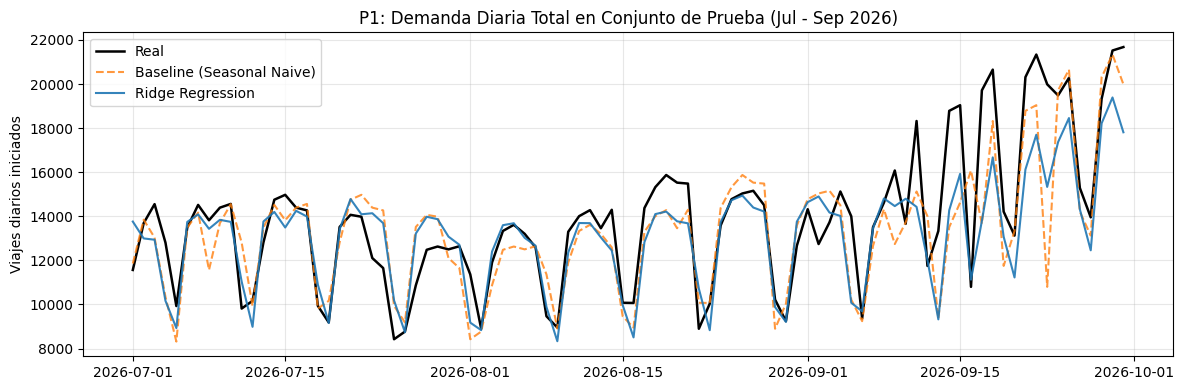

In [5]:
test_df['pred_baseline'] = test_df['lag_7d']
test_df['pred_ridge'] = np.clip(ridge_model.predict(test_df[num_cols + cat_cols]), 0, None)

daily_test_summary = test_df.groupby('date')[['trips_count', 'pred_baseline', 'pred_ridge']].sum()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily_test_summary.index, daily_test_summary['trips_count'], label='Real', color='black', linewidth=1.8)
ax.plot(daily_test_summary.index, daily_test_summary['pred_baseline'], label='Baseline (Seasonal Naive)', color='#ff7f0e', linestyle='--', alpha=0.8)
ax.plot(daily_test_summary.index, daily_test_summary['pred_ridge'], label='Ridge Regression', color='#1f77b4', alpha=0.9)
ax.set_title('P1: Demanda Diaria Total en Conjunto de Prueba (Jul - Sep 2026)')
ax.set_ylabel('Viajes diarios iniciados')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusiones
- Granularidad diaria por estación y horizonte de 1 día, para que el operador planee la asignación diaria de flota.
- Los rezagos se calculan con `shift(1..21)` ordenados por estación y fecha; `StandardScaler` y `OneHotEncoder` se ajustan solo con `Train` (2024–2025).
- La demanda tiene estacionalidad semanal marcada (baja en fin de semana, picos de martes a jueves).
- Ridge mejora al *Seasonal Naive* (`lag_7d`) en `MAE`, `RMSE` y `WAPE` en validación y prueba.

Siguiente paso: mover la construcción de variables a `mi_bici/features.py` y registrar los dos runs en MLflow desde `mi_bici/modeling/train.py`.